# Análisis del modelo final: `mlp_v1.0.0`

¿**Cómo** predice el modelo de producción el frío (kW) del día siguiente? Este notebook:

1. Carga `mlp_v1.0.0` **desde el registro** (verifica el sha256) y lo mide en **test**, el 15 % final de los
   días que ningún modelo vio (ni en Optuna ni en el entrenamiento final, que usó train + val).
2. Explica sus predicciones con **SHAP**: qué variables pesan, en qué dirección y cómo se arma una predicción.
3. Termina con un **dashboard** (ipywidgets + matplotlib) que muestra la forma de la red y lo que pasa
   adentro para el día que se elija, con controles *what-if*.

Los gráficos se guardan en `reports/figuras/` y se usan en la sección "El modelo" del README.

## Configuración

In [1]:
import re
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import shap.plots._style as shap_estilo
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# raíz del proyecto = la primera carpeta (desde acá hacia arriba) que tiene src/preprocess.py
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "preprocess.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from predict import load_model
from preprocess import COL_FECHA, TARGET, cargar_dataset_limpio
from train_model import _sin_avisos, cargar_config, crear_preprocess

MODELO, VERSION = "mlp", "v1.0.0"
SEMILLA = 42
N_FONDO = 100            # días de train+val que usa SHAP como referencia ("fondo")
FIGURAS = ROOT / "reports" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

# paleta de referencia (la misma que notebooks/modelado.ipynb)
TINTA, TINTA_2, MUDO, GRILLA, EJE, FONDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
AZUL, NARANJA, ROJO, NEUTRO = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", [AZUL, NEUTRO, ROJO])      # negativo / 0 / positivo
SECUENCIAL = LinearSegmentedColormap.from_list("secuencial", ["#86b6ef", "#0d366b"])     # bajo -> alto
KW = FuncFormatter(lambda v, _: f"{v:,.0f}")

plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": TINTA, "axes.labelcolor": TINTA_2, "axes.edgecolor": MUDO,
    "xtick.color": MUDO, "ytick.color": MUDO, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "legend.frameon": False,
})
# SHAP: aporte positivo (más consumo) en rojo, negativo en azul, igual que el mapa divergente
shap_estilo.set_style(primary_color_positive=ROJO, primary_color_negative=AZUL,
                      secondary_color_positive="#f1a4a3", secondary_color_negative="#9ec5f4",
                      hlines_color=GRILLA, vlines_color=MUDO, tick_labels_color=MUDO)


def estilo(ax, grilla="y"):
    if grilla:
        ax.grid(axis=grilla, color=GRILLA, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)


def traducir_shap(fig):
    """Etiquetas en inglés de los gráficos de SHAP ("Sum of 14 other features", "17 other features")."""
    for ax in fig.axes:
        etiquetas = [t.get_text() for t in ax.get_yticklabels()]
        if any("other feature" in e for e in etiquetas):
            ax.set_yticks(ax.get_yticks(), [re.sub(r"(?:Sum of )?(\d+) other features?", r"otras \1 variables", e)
                                            for e in etiquetas])


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

## Modelo y datos

`mlp_v1.0.0` es un `PipelineFrio` (`src/train_model.py`): `agregar_derivadas` → `Preprocess` → escalado
(`RobustScaler`) y selección de variables → `MLPRegressor` con el target estandarizado. Se separan sus partes:

- `pipe.transformar(df)`: días limpios → todas las variables tratadas (derivadas + `Preprocess`).
- `modelo[:-1]`: escalado + selección → las **26 variables** que entran a la red, ya escaladas (`Z`).
- `red = modelo[-1]`: la red en sí (`TransformedTargetRegressor`); `red.predict(Z)` devuelve kW.

El split train / val / test se arma con el mismo `Preprocess` del linaje del dataset, así que las fechas de test
son exactamente las que quedaron reservadas. Para predecir test se le pasa toda la historia anterior (los lags y
medias móviles miran hasta 14 días hacia atrás).

In [2]:
modelo, pipe = load_model(MODELO, VERSION)       # verifica el sha256 del .joblib contra el registro
red = modelo[-1]                                 # TransformedTargetRegressor (MLP + escalado del target)
mlp = red.regressor_                             # MLPRegressor entrenado
COLS = pipe.columnas_                            # las 26 variables que entran a la red

cfg = cargar_config(MODELO, VERSION)
train, val, test = crear_preprocess(cfg["linaje"]).train_test_split(cargar_dataset_limpio())
todo = pd.concat([train, val, test])
fechas_test = pd.DatetimeIndex(pd.to_datetime(test[COL_FECHA]))

X = pipe.transformar(todo)                       # todas las variables tratadas, índice = fecha
Z = modelo[:-1].transform(X)                     # las 26 de la red, escaladas
assert list(Z.columns) == COLS
es_test = X.index.isin(fechas_test)
with _sin_avisos():
    pred = pd.Series(modelo.predict(X), index=X.index, name="pred")
real = todo.set_index(COL_FECHA)[TARGET]         # frío del día D+1 (fila = día D)

print(f"train {len(train)} días | val {len(val)} | test {len(test)} "
      f"({fechas_test.min():%Y-%m-%d} a {fechas_test.max():%Y-%m-%d})")
print(f"{X.shape[1]} variables tratadas -> {len(COLS)} entran a la red")

Modelo: mlp v1.0.0 (models/mlp_v1.0.0.joblib)


train 848 días | val 182 | test 182 (2023-04-27 a 2023-10-25)
390 variables tratadas -> 26 entran a la red


In [3]:
capas = [len(COLS), *mlp.hidden_layer_sizes, 1]
arquitectura = pd.DataFrame({
    "capa": ["entrada", *[f"oculta {i + 1}" for i in range(len(mlp.hidden_layer_sizes))], "salida"],
    "neuronas": capas,
    "activación": ["—", *[mlp.activation] * len(mlp.hidden_layer_sizes), mlp.out_activation_],
    "parámetros": [0, *[W.size + b.size for W, b in zip(mlp.coefs_, mlp.intercepts_)]],
})
print(f"Total de parámetros: {arquitectura['parámetros'].sum():,} | iteraciones de entrenamiento: {mlp.n_iter_} | "
      f"alpha (L2) {mlp.alpha:.3g} | lr {mlp.learning_rate_init:.2g}")
arquitectura

Total de parámetros: 14,273 | iteraciones de entrenamiento: 273 | alpha (L2) 1.14 | lr 0.00019


,capa,neuronas,activación,parámetros
0,entrada,26,—,0
1,oculta 1,64,tanh,1728
2,oculta 2,64,tanh,4160
3,oculta 3,64,tanh,4160
4,oculta 4,64,tanh,4160
5,salida,1,identity,65


## Desempeño en test

Referencia: la **persistencia** (el frío de mañana = el de hoy), el baseline contra el que se compararon todos los
modelos en `modelado.ipynb`. El último día de test no tiene "mañana" y queda afuera de las métricas.

In [4]:
yt, pt = real.loc[fechas_test], pred.loc[fechas_test]
ok = yt.notna()
persistencia = todo.set_index(COL_FECHA)["frio (kw)"].loc[fechas_test]


def metricas(y, p):
    return {"MAE (kW)": mean_absolute_error(y, p), "RMSE (kW)": np.sqrt(mean_squared_error(y, p)),
            "R²": r2_score(y, p)}


tabla_test = pd.DataFrame({"mlp v1.0.0": metricas(yt[ok], pt[ok]),
                           "persistencia": metricas(yt[ok], persistencia[ok])}).T
mejora = 100 * (1 - tabla_test.loc["mlp v1.0.0", "MAE (kW)"] / tabla_test.loc["persistencia", "MAE (kW)"])
print(f"El MLP baja el MAE {mejora:.1f} % respecto a la persistencia ({ok.sum()} días de test)")
tabla_test.style.format({"MAE (kW)": "{:,.0f}", "RMSE (kW)": "{:,.0f}", "R²": "{:.3f}"})

El MLP baja el MAE 15.6 % respecto a la persistencia (181 días de test)


,MAE (kW),RMSE (kW),R²
mlp v1.0.0,"2,796","3,641",0.601
persistencia,"3,312","4,347",0.431


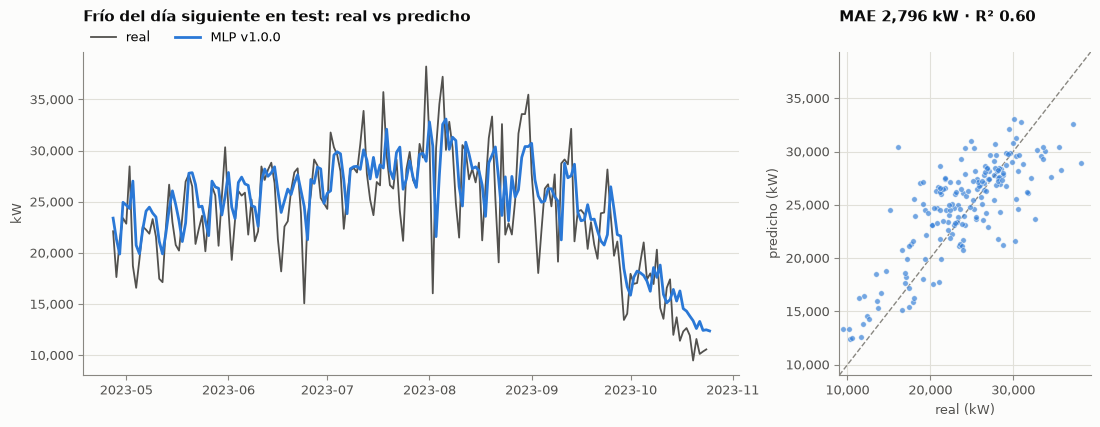

In [5]:
error = (pt - yt)[ok]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1.15], "wspace": 0.22})
ax.plot(yt.index, yt, color=TINTA_2, linewidth=1.3, label="real")
ax.plot(pt.index, pt, color=AZUL, linewidth=2, label="MLP v1.0.0")
ax.set_title("Frío del día siguiente en test: real vs predicho", pad=22)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9, borderaxespad=0.2)
ax.set_ylabel("kW")
ax.yaxis.set_major_formatter(KW)
estilo(ax)

lim = [min(yt[ok].min(), pt.min()) * 0.95, max(yt[ok].max(), pt.max()) * 1.03]
ax2.plot(lim, lim, color=MUDO, linewidth=1, linestyle="--", zorder=1)
ax2.scatter(yt[ok], pt[ok], s=16, color=AZUL, alpha=0.65, edgecolor=FONDO, linewidth=0.5, zorder=2)
ax2.set(xlim=lim, ylim=lim, xlabel="real (kW)", ylabel="predicho (kW)")
ax2.set_title(f"MAE {tabla_test.iloc[0, 0]:,.0f} kW · R² {tabla_test.iloc[0, 2]:.2f}", pad=22)
ax2.xaxis.set_major_formatter(KW)
ax2.yaxis.set_major_formatter(KW)
estilo(ax2, "both")
guardar(fig, "test_real_vs_pred")
plt.show()

**Lectura.** En los 181 días de test el MLP tiene un MAE de **≈2,800 kW** (R² 0.60) contra ≈3,310 kW de la
persistencia: **≈16 % menos error**. Sigue bien el nivel y la estacionalidad (sube en verano y acompaña la baja de
octubre), pero **suaviza**: no anticipa las caídas bruscas de un solo día (p. ej. 3 de agosto, ver el waterfall más
abajo), que no tienen ninguna señal en los datos del día anterior. En promedio sobreestima ≈800 kW, sobre todo en
octubre, cuando el consumo cae más rápido de lo que el modelo espera.

## SHAP: por qué el modelo predice lo que predice

Para cada día, SHAP reparte la predicción entre las 26 variables:

$$\text{predicción} = \underbrace{E[f(X)]}_{\text{base}} + \sum_{j=1}^{26} \phi_j$$

- La **base** es la predicción media sobre el fondo (100 días de train + val).
- $\phi_j$ es el aporte (en **kW**) de la variable $j$ ese día: positivo empuja la predicción hacia arriba.

Se explica solo la red (`red.predict` sobre las 26 variables escaladas) con el *Permutation explainer*, que es
exacto en la aditividad. Como el `RobustScaler` es una transformación lineal creciente por columna, los gráficos
muestran las variables **en sus unidades reales** (kW, °C, hl, %) sin cambiar los $\phi$.

Ojo: muchas variables están muy correlacionadas (la temperatura de hoy y sus medias móviles, el frío y sus
promedios). SHAP con fondo independiente reparte el efecto entre ellas, así que conviene leer también la
importancia **por grupo**.

In [6]:
def f_red(z):
    """Red neuronal sobre las 26 variables escaladas -> kW."""
    return red.predict(pd.DataFrame(z, columns=COLS))


Z_fondo = shap.sample(Z[~es_test], N_FONDO, random_state=SEMILLA)
explicador = shap.Explainer(f_red, shap.maskers.Independent(Z_fondo.values, max_samples=N_FONDO),
                            algorithm="permutation", feature_names=COLS, seed=SEMILLA)
X_test = X.loc[fechas_test, COLS]
crudo = explicador(Z.loc[fechas_test].values, silent=True)
sv = shap.Explanation(values=crudo.values, base_values=crudo.base_values, data=X_test.values, feature_names=COLS)
base = float(sv.base_values[0])

# aditividad: base + suma de aportes = predicción del modelo completo
assert np.allclose(sv.base_values + sv.values.sum(axis=1), pt.values, atol=1e-2)
print(f"Base E[f(X)] = {base:,.0f} kW | {sv.shape[0]} días de test explicados")

importancia = pd.Series(np.abs(sv.values).mean(axis=0), index=COLS).sort_values(ascending=False)
importancia.round(0).to_frame("mean |SHAP| (kW)").head(10)

Base E[f(X)] = 23,025 kW | 182 días de test explicados


,mean |SHAP| (kW)
mes_cos,966.0
frio (kw),896.0
hl cerveza envasada,624.0
frio (kw) mm7,580.0
hl cerveza envasada lag1,570.0
sala maq (kw),527.0
mes_sin,516.0
servicios (kw),497.0
frio (kw) mm3,422.0
hl cerveza envasada mm14,258.0


### Importancia global
Cuántos kW mueve en promedio cada variable la predicción (media de $|\phi_j|$ en test).

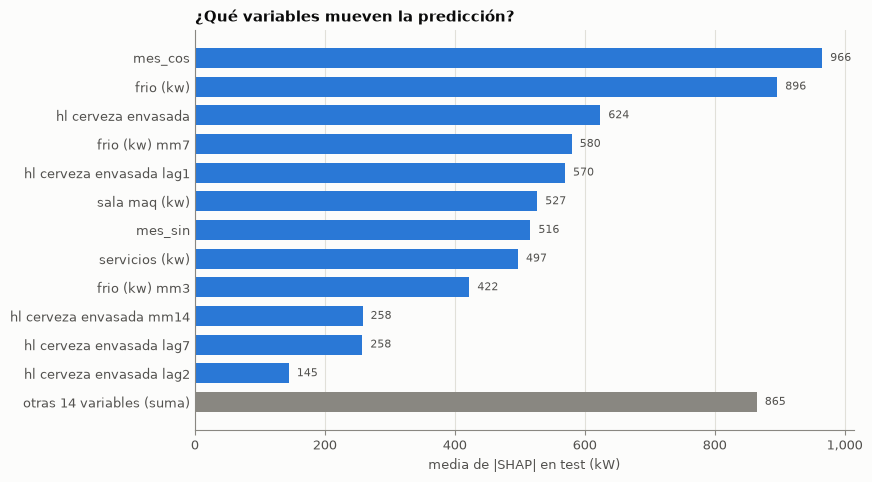

In [7]:
N_TOP = 12
top = importancia.head(N_TOP)[::-1]
resto = importancia.iloc[N_TOP:]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh([f"otras {len(resto)} variables (suma)"], [resto.sum()], color=MUDO, height=0.7)
ax.barh(top.index, top.values, color=AZUL, height=0.7)
for i, v in enumerate([resto.sum(), *top.values]):
    ax.text(v, i, f"  {v:,.0f}", va="center", fontsize=8, color=TINTA_2)
ax.set_xlabel("media de |SHAP| en test (kW)")
ax.set_title("¿Qué variables mueven la predicción?")
ax.xaxis.set_major_formatter(KW)
ax.tick_params(axis="y", length=0)
estilo(ax, "x")
guardar(fig, "shap_importancia")
plt.show()

### Dirección del efecto (beeswarm)
Cada punto es un día de test. Eje x: aporte $\phi$ (kW); color: valor de la variable ese día (claro = bajo,
oscuro = alto). Si los puntos oscuros están a la derecha, valores altos de la variable suben la predicción.

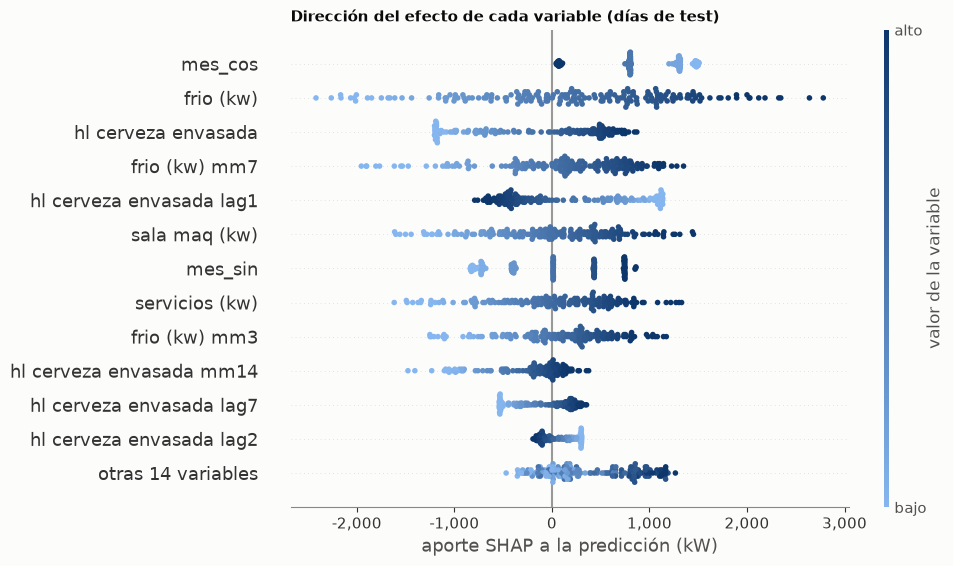

In [8]:
plt.figure()
shap.plots.beeswarm(sv, max_display=13, color=SECUENCIAL, show=False, plot_size=(9, 6.2),
                    color_bar_label="valor de la variable")
fig = plt.gcf()
ax = fig.axes[0]
ax.set_xlabel("aporte SHAP a la predicción (kW)")
ax.set_title("Dirección del efecto de cada variable (días de test)")
ax.xaxis.set_major_formatter(KW)
barra = fig.axes[-1]
barra.set_yticklabels(["bajo", "alto"])
traducir_shap(fig)
guardar(fig, "shap_beeswarm")
plt.show()

**Lectura.**
- **`frio (kw)` y sus medias móviles**: cuanto más frío se consumió hoy (y en la última semana), más se predice para
  mañana. Es la "persistencia" que el modelo aprendió, pero repartida entre hoy, 3 y 7 días.
- **`mes_cos` / `mes_sin`**: todo test cae entre mayo y octubre. Los meses de pleno verano (`mes_cos` ≈ −1, puntos
  claros) suman hasta **+1,500 kW**; octubre (`mes_cos` = 0) casi no aporta.
- **Producción**: `hl cerveza envasada` alta sube la predicción, pero `hl cerveza envasada lag1` tiene el signo
  **contrario**. Son variables muy correlacionadas y la red usa en parte su diferencia (cuánto cambió la producción
  respecto de ayer); por eso conviene mirar el efecto del grupo completo.
- **`sala maq (kw)` y `servicios (kw)`**: más consumo eléctrico de planta hoy → más frío mañana.

### Importancia por grupo de variables
SHAP es aditivo: el aporte de un grupo es la suma de los aportes de sus variables. Agrupar evita que el efecto
de variables casi idénticas (p. ej. la temperatura de hoy y su media de 3 días) se vea "diluido".

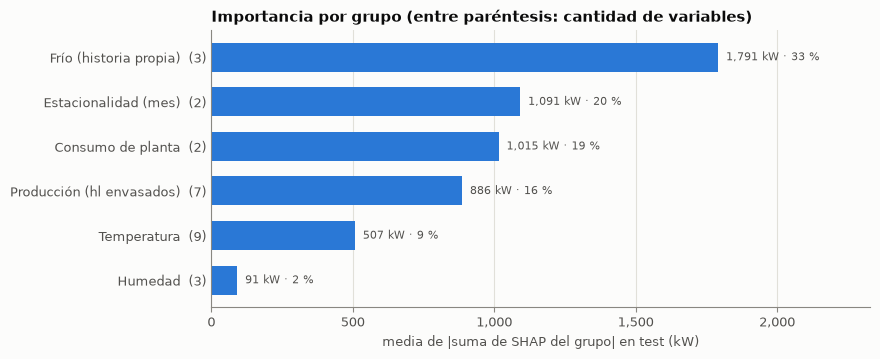

In [9]:
def grupo(col):
    if col.startswith("frio"):
        return "Frío (historia propia)"
    if col in ("servicios (kw)", "sala maq (kw)"):
        return "Consumo de planta"
    if col.startswith("hl cerveza"):
        return "Producción (hl envasados)"
    if col.startswith("temp"):
        return "Temperatura"
    if col.startswith("humedad"):
        return "Humedad"
    if col.startswith("mes"):
        return "Estacionalidad (mes)"
    raise KeyError(col)


sv_grupo = pd.DataFrame(sv.values, columns=COLS, index=fechas_test).T.groupby(grupo).sum().T
imp_grupo = sv_grupo.abs().mean().sort_values()
n_vars = pd.Series([grupo(c) for c in COLS]).value_counts()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.barh([f"{g}  ({n_vars[g]})" for g in imp_grupo.index], imp_grupo.values, color=AZUL, height=0.65)
for i, v in enumerate(imp_grupo.values):
    ax.text(v, i, f"  {v:,.0f} kW · {100 * v / imp_grupo.sum():.0f} %", va="center", fontsize=8, color=TINTA_2)
ax.set_xlabel("media de |suma de SHAP del grupo| en test (kW)")
ax.set_title("Importancia por grupo (entre paréntesis: cantidad de variables)")
ax.xaxis.set_major_formatter(KW)
ax.set_xlim(0, imp_grupo.max() * 1.3)
ax.tick_params(axis="y", length=0)
estilo(ax, "x")
guardar(fig, "shap_grupos")
plt.show()

**Lectura.** Un tercio de lo que mueve la predicción es la **historia del propio frío**; le siguen la
**estacionalidad** (20 %), el **consumo de planta** (19 %) y la **producción** (16 %). La **temperatura** pesa solo
un 9 % pese a tener 9 variables: buena parte del efecto del calor ya está en el mes y en el frío reciente (que
sube con el calor), así que la temperatura del día agrega poco por encima de eso. La humedad casi no se usa.

### Forma del efecto (dependencia)
Para las 4 variables más importantes: aporte $\phi$ vs valor de la variable. Una nube recta indica un efecto casi
lineal; una curva que se aplana, saturación (la `tanh` de la red lo permite). La dispersión vertical para un
mismo valor viene de las interacciones con las demás variables.

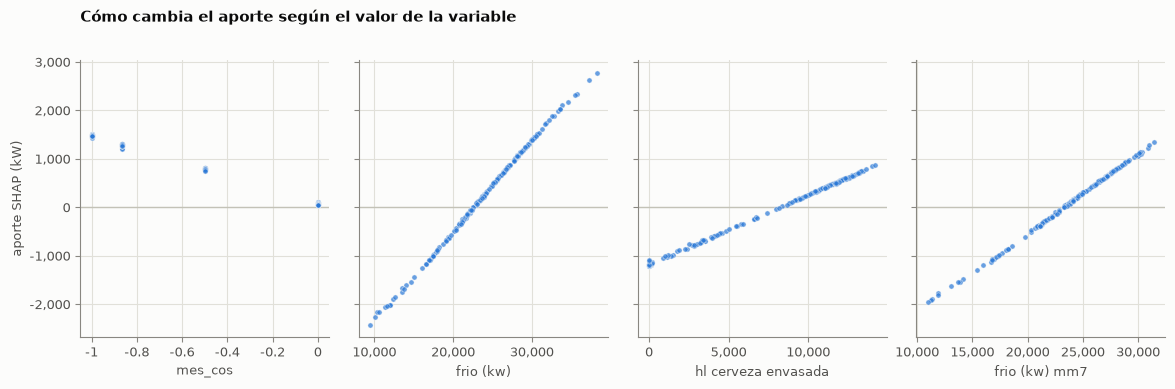

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, col in zip(axs, importancia.index[:4]):
    j = COLS.index(col)
    ax.axhline(0, color=EJE, linewidth=1, zorder=1)
    ax.scatter(sv.data[:, j], sv.values[:, j], s=14, color=AZUL, alpha=0.7, edgecolor=FONDO, linewidth=0.4, zorder=2)
    ax.set_xlabel(col)
    ax.xaxis.set_major_formatter(KW if X_test[col].abs().max() > 1000 else FuncFormatter(lambda v, _: f"{v:g}"))
    estilo(ax, "both")
axs[0].set_ylabel("aporte SHAP (kW)")
axs[0].yaxis.set_major_formatter(KW)
fig.suptitle("Cómo cambia el aporte según el valor de la variable", x=0.125, ha="left", fontweight="bold",
             fontsize=11, color=TINTA, y=1.02)
guardar(fig, "shap_dependencia")
plt.show()

**Lectura.** Las nubes son **líneas rectas casi perfectas** (lo mismo pasa con las 26 variables: la correlación
entre valor y aporte es ±1.00). Pese a tener 4 capas `tanh` y 14 mil parámetros, en el rango de los datos **la red se
comporta como una regresión lineal**: cada kW de frío de hoy suma ≈0.19 kW a la predicción de mañana, cada hl
envasado ≈0.14 kW y cada °C de la temperatura media de 14 días ≈28 kW. La sección "La red por dentro" muestra por qué.

### Una predicción explicada (waterfall)
Dos días de test: uno **típico** (error absoluto igual a la mediana) y el **peor** (mayor error absoluto). Se parte
de la base $E[f(X)]$ abajo y cada barra suma (rojo) o resta (azul) kW hasta llegar a la predicción $f(x)$ arriba.

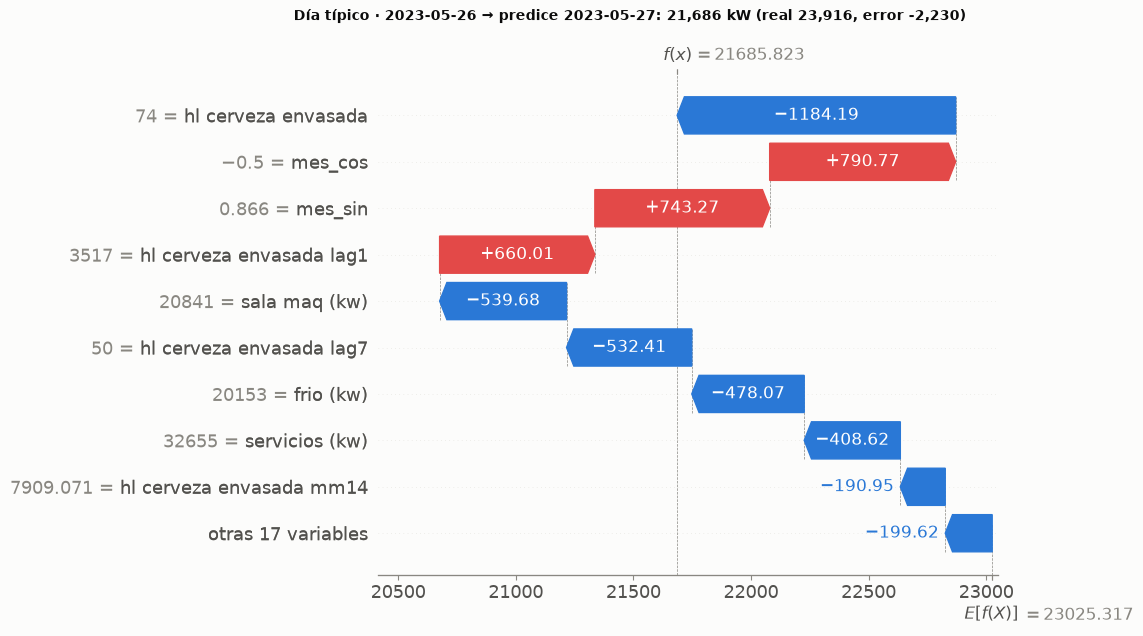

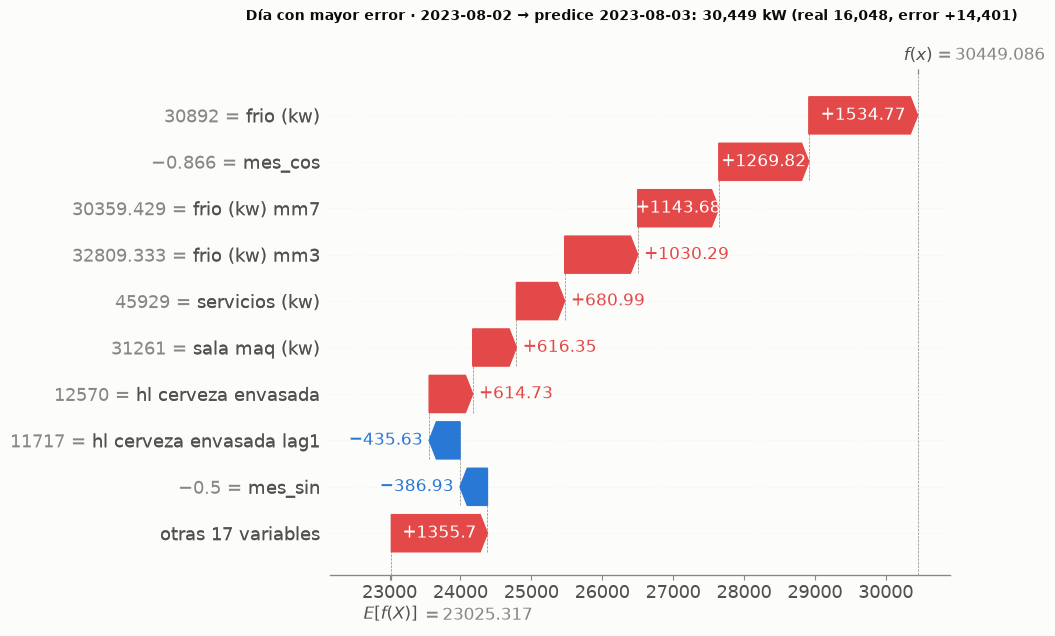

In [11]:
error_abs = error.abs()
fecha_tipica = (error_abs - error_abs.median()).abs().idxmin()
fecha_peor = error_abs.idxmax()


def waterfall(fecha, nombre, etiqueta):
    i = fechas_test.get_loc(fecha)
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    fig = plt.gcf()
    traducir_shap(fig)
    lo, hi = fig.axes[0].get_xlim()          # margen a la izquierda para que los números no pisen las etiquetas
    for ax in fig.axes:
        ax.set_xlim(lo - 0.1 * (hi - lo), hi)
    fig.suptitle(f"Día {etiqueta} · {fecha:%Y-%m-%d} → predice {fecha + pd.Timedelta(days=1):%Y-%m-%d}: "
                 f"{pt[fecha]:,.0f} kW (real {yt[fecha]:,.0f}, error {pt[fecha] - yt[fecha]:+,.0f})",
                 x=0.02, ha="left", fontsize=10, fontweight="bold", color=TINTA)
    guardar(fig, nombre)
    plt.show()


waterfall(fecha_tipica, "shap_waterfall_tipico", "típico")
waterfall(fecha_peor, "shap_waterfall_peor", "con mayor error")

**Lectura.**
- **Día típico (26/05)**: ese día casi no se envasó (74 hl), lo que resta ≈1,200 kW; el mes (fines de mayo) suma
  ≈1,500 kW, y un consumo de planta algo bajo resta otros ≈950. Termina en 21,686 kW contra 23,916 reales.
- **Peor día (02/08 → 03/08)**: todo indicaba un día alto (frío de hoy ≈30,900 kW, semana alta, pleno verano,
  producción alta) y el modelo predijo 30,449 kW; el real fue **16,048 kW**. La caída no se veía en los datos del día
  D (probablemente una parada o mantenimiento), así que ningún modelo basado en esas variables podría anticiparla.

## La red por dentro

Con los pesos (`mlp.coefs_`) y sesgos (`mlp.intercepts_`) se puede rehacer la predicción a mano, capa por capa:

$$h_0 = z,\qquad h_k = \tanh(h_{k-1} W_k + b_k)\ \ (k = 1..4),\qquad \hat y = \text{desescalar}(h_4 W_5 + b_5)$$

Si la cuenta a mano coincide con `modelo.predict`, las activaciones que se muestran son las reales.

In [12]:
def propagar(z):
    """z: (n, 26) escaladas -> (activaciones [h0, h1, ..., salida escalada], predicción en kW)."""
    h = np.atleast_2d(np.asarray(z, dtype=float))
    acts = [h]
    for k, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_)):
        h = h @ W + b
        if k < len(mlp.coefs_) - 1:
            h = np.tanh(h)
        acts.append(h)
    return acts, red.transformer_.inverse_transform(h).ravel()


acts_test, kw_test = propagar(Z.loc[fechas_test])
assert np.allclose(kw_test, pt.values, atol=1e-6)
print("La propagación a mano reproduce modelo.predict en los", len(kw_test), "días de test")

saturacion = pd.DataFrame({
    "capa": [f"oculta {k}" for k in range(1, len(acts_test) - 1)],
    "% activaciones saturadas (|h| > 0.95)": [100 * (np.abs(a) > 0.95).mean() for a in acts_test[1:-1]],
    "neuronas casi constantes (std < 0.05)": [int((a.std(axis=0) < 0.05).sum()) for a in acts_test[1:-1]],
    "|h| medio": [np.abs(a).mean() for a in acts_test[1:-1]],
})
saturacion.round(2)

La propagación a mano reproduce modelo.predict en los 182 días de test


,capa,% activaciones saturadas (|h| > 0.95),neuronas casi constantes (std < 0.05),|h| medio
0,oculta 1,0.0,12,0.15
1,oculta 2,0.0,15,0.12
2,oculta 3,0.0,15,0.13
3,oculta 4,0.0,22,0.12


### Forma de la red: pesos y activaciones
Arriba, las 5 matrices de pesos (filas = neuronas de entrada a la capa, columnas = neuronas de salida; rojo
positivo, azul negativo, escala propia por matriz). Abajo, cómo se distribuyen las activaciones `tanh` de cada
capa oculta en todos los días de test: si se amontonan en ±1 la capa está saturada.

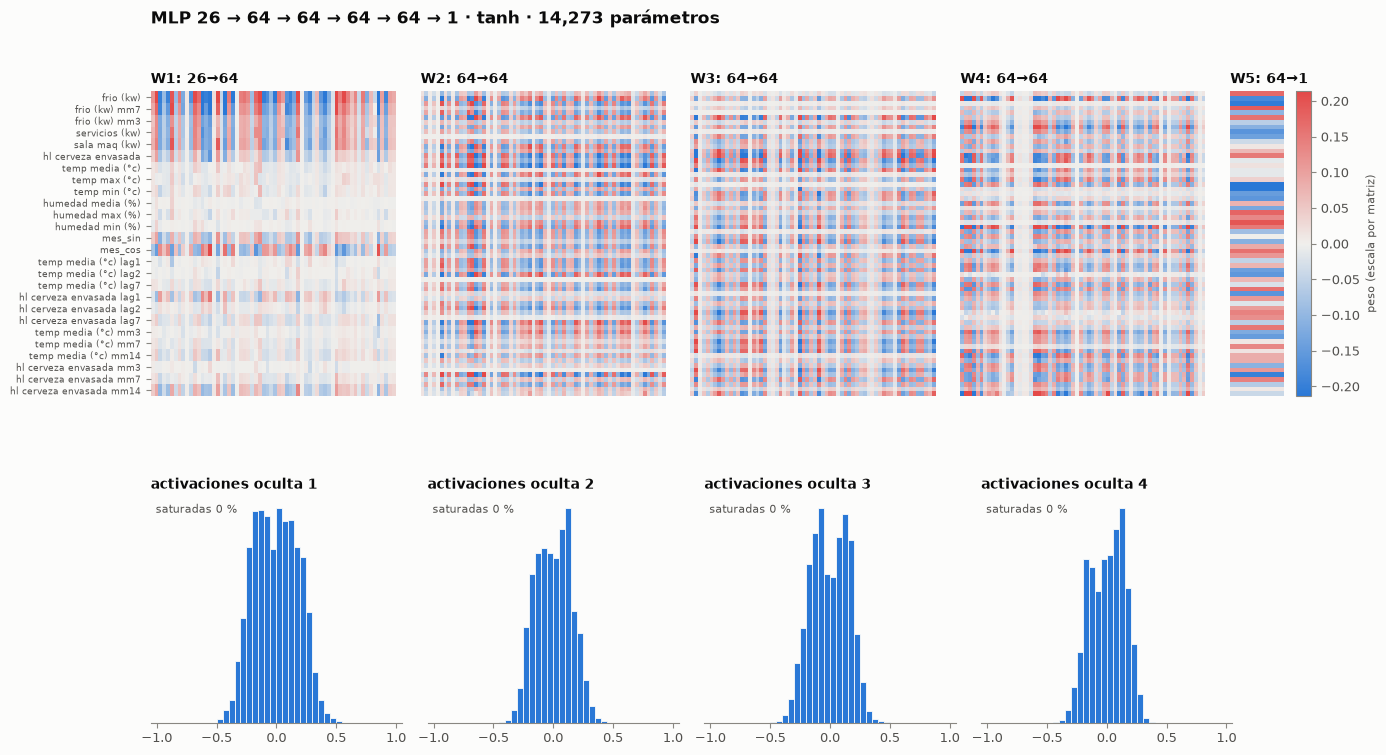

In [13]:
fig = plt.figure(figsize=(15, 8.2))
gs = fig.add_gridspec(2, 5, height_ratios=[1.35, 1], width_ratios=[1, 1, 1, 1, 0.22], hspace=0.38, wspace=0.12)
for k, W in enumerate(mlp.coefs_):
    ax = fig.add_subplot(gs[0, k])
    v = np.quantile(np.abs(W), 0.99)
    im = ax.imshow(W, aspect="auto", cmap=DIVERGENTE, vmin=-v, vmax=v, interpolation="nearest")
    ax.set_title(f"W{k + 1}: {W.shape[0]}→{W.shape[1]}", fontsize=10)
    ax.set_xticks([])
    if k == 0:
        ax.set_yticks(range(len(COLS)), COLS, fontsize=6.5)
    else:
        ax.set_yticks([])
    for lado in ax.spines.values():
        lado.set_visible(False)
fig.colorbar(im, ax=fig.axes[:5], fraction=0.015, pad=0.01).set_label("peso (escala por matriz)", fontsize=8)

for k, a in enumerate(acts_test[1:-1]):
    ax = fig.add_subplot(gs[1, k])
    ax.hist(a.ravel(), bins=np.linspace(-1, 1, 41), color=AZUL, edgecolor=FONDO, linewidth=0.6)
    ax.set_title(f"activaciones oculta {k + 1}", fontsize=10)
    ax.text(0.02, 0.97, f"saturadas {100 * (np.abs(a) > 0.95).mean():.0f} %", transform=ax.transAxes,
            va="top", fontsize=8, color=TINTA_2)
    ax.set_xlim(-1.05, 1.05)
    ax.set_yticks([])
    estilo(ax, None)
    ax.spines["left"].set_visible(False)
fig.suptitle(f"MLP {' → '.join(map(str, capas))} · tanh · {arquitectura['parámetros'].sum():,} parámetros",
             x=0.125, ha="left", fontsize=12, fontweight="bold", color=TINTA)
guardar(fig, "red_forma")
plt.show()

**Lectura.**
- **W1** (entrada → oculta 1): las filas con pesos fuertes son el frío, `servicios`, `sala maq`, la producción y el
  mes; las de **temperatura y humedad están casi en blanco**. Coincide con lo que dice SHAP.
- **Activaciones**: todas quedan entre ≈ −0.5 y 0.5 y **ninguna se satura**. En ese rango `tanh(x) ≈ x`, así que
  cada capa es casi lineal y la red entera también: por eso las curvas de dependencia son rectas. La regularización
  L2 (`alpha` ≈ 1.1) y la tasa de aprendizaje chica que eligió Optuna mantienen los pesos chicos.
- Además, entre 12 y 22 neuronas por capa casi no cambian de un día a otro (desvío < 0.05): la red tiene capacidad
  de sobra que no usa.

## Dashboard: el MLP funcionando

Elegí un **día D de test** y mirá cómo la red llega a la predicción del frío de **D+1**:

- **Arriba**: la red completa. Cada nodo es una neurona coloreada por su valor ese día (entrada: variable escalada;
  ocultas: activación `tanh`). Las líneas son los aportes más fuertes $h_i \cdot w_{ij}$ que llegan a la capa
  siguiente (rojo suma, azul resta).
- **Medio**: los aportes SHAP del día (por qué predice eso) y dónde cae el día en la serie de test.
- **Abajo**: qué neuronas se activan distinto a lo habitual (activación del día − media en test) y curvas
  *what-if*: cómo cambiaría la predicción si se moviera solo una variable (la más importante de cada grupo:
  frío, producción, consumo de planta y temperatura).

Los colores de los nodos usan la escala de lo que realmente toman las neuronas (no ±1): la red trabaja lejos de la
saturación de la `tanh`. Los sliders *what-if* cambian el valor de esas variables para el día elegido (el resto queda igual) y todo el
tablero se recalcula; el punto naranja es la predicción modificada. Al mover una variable no se mueven sus
derivadas (p. ej. cambiar `frio (kw)` no cambia `frio (kw) mm3`), así que valores extremos pueden ser combinaciones
que no ocurren en la realidad.

*El dashboard necesita un kernel corriendo (en GitHub solo se ve la imagen estática de la celda siguiente).*

In [14]:
# what-if: la variable más importante de cada grupo que se puede "mover" (el mes no)
WHATIF = [next(c for c in importancia.index if grupo(c) == g)
          for g in ("Frío (historia propia)", "Producción (hl envasados)", "Consumo de planta", "Temperatura")]
rango = X[WHATIF].quantile([0.01, 0.99])
media_act = [a.mean(axis=0) for a in acts_test]
N_LINEAS = 28                  # aportes h·w más fuertes que se dibujan entre cada par de capas
# escalas de color según lo que de verdad toman las neuronas (las activaciones son chicas: |h| medio ~0.15)
ESCALA_IN = float(np.quantile(np.abs(acts_test[0]), 0.98))
ESCALA_H = float(np.quantile(np.abs(np.hstack(acts_test[1:-1])), 0.98))
ESCALA_DESVIO = float(np.quantile(np.abs(np.hstack([a - a.mean(axis=0) for a in acts_test[1:-1]])), 0.98))


def entrada(fecha, ajustes=None):
    """Fila de X del día con los ajustes what-if -> (variables tratadas, Z escaladas)."""
    x = X.loc[[fecha]].copy()
    for col, v in (ajustes or {}).items():
        x[col] = v
    return x, modelo[:-1].transform(x)


def _red(ax, acts, ajustes):
    tam = [len(a) for a in acts]
    xs = np.arange(len(tam))
    ys = [np.linspace(1, 0, n) if n > 1 else np.array([0.5]) for n in tam]
    # aportes h_i * w_ij más fuertes entre capas consecutivas
    for k, W in enumerate(mlp.coefs_):
        aporte = acts[k][:, None] * W
        idx = np.argsort(np.abs(aporte), axis=None)[-N_LINEAS:]
        top = np.abs(aporte).ravel()[idx].max()
        for i, j in zip(*np.unravel_index(idx, aporte.shape)):
            a = aporte[i, j]
            ax.plot([xs[k], xs[k + 1]], [ys[k][i], ys[k + 1][j]], color=ROJO if a > 0 else AZUL,
                    linewidth=0.4 + 2.4 * abs(a) / top, alpha=0.25 + 0.5 * abs(a) / top, zorder=1)
    norma_in, norma_h = Normalize(-ESCALA_IN, ESCALA_IN), Normalize(-ESCALA_H, ESCALA_H)
    for k, (a, y) in enumerate(zip(acts, ys)):
        if k == len(acts) - 1:
            continue
        color = DIVERGENTE(norma_in(a) if k == 0 else norma_h(a))
        ax.scatter(np.full(len(a), xs[k]), y, s=34 if k == 0 else 20, c=color, edgecolor=MUDO, linewidth=0.4,
                   zorder=3)
    for i, col in enumerate(COLS):
        ax.text(xs[0] - 0.06, ys[0][i], col, ha="right", va="center", fontsize=6.5,
                color=NARANJA if col in (ajustes or {}) else TINTA_2,
                fontweight="bold" if col in (ajustes or {}) else "normal")
    ax.scatter([xs[-1]], [0.5], s=420, color=AZUL, edgecolor=MUDO, zorder=3)
    nombres = ["entrada\n26 variables (escaladas)", *[f"oculta {k}\n64 · tanh" for k in range(1, len(tam) - 1)],
               "salida\nkW de D+1"]
    for x_, n in zip(xs, nombres):
        ax.text(x_, -0.075, n, ha="center", va="top", fontsize=8, color=TINTA_2)
    ax.set_xlim(-1.35, xs[-1] + 0.45)
    ax.set_ylim(-0.17, 1.03)
    ax.axis("off")
    return xs, ys


def _shap(ax, s, x_crudo):
    orden = np.argsort(np.abs(s))[::-1]
    top, resto = orden[:9], orden[9:]
    valores = [s[resto].sum(), *s[top][::-1]]
    etiquetas = [f"otras {len(resto)}"] + [
        f"{COLS[j]} = {x_crudo[j]:,.0f}" if abs(x_crudo[j]) >= 100 else f"{COLS[j]} = {x_crudo[j]:.2f}"
        for j in top[::-1]]
    colores = [MUDO] + [ROJO if v > 0 else AZUL for v in s[top][::-1]]
    ax.barh(range(len(valores)), valores, color=colores, height=0.68, zorder=2)
    ax.set_yticks(range(len(valores)), etiquetas, fontsize=7.5)
    ax.axvline(0, color=EJE, linewidth=1, zorder=1)
    lim = np.abs(valores).max() * 1.35
    ax.set_xlim(-lim, lim)
    for i, v in enumerate(valores):
        ax.text(v, i, f" {v:+,.0f} " if v >= 0 else f" {v:+,.0f} ", va="center", ha="left" if v >= 0 else "right",
                fontsize=7, color=TINTA_2)
    ax.xaxis.set_major_formatter(KW)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("aporte SHAP (kW)")
    estilo(ax, "x")


def _serie(ax, fecha, kw_mod):
    ax.plot(yt.index, yt, color=TINTA_2, linewidth=1.1, label="real")
    ax.plot(pt.index, pt, color=AZUL, linewidth=1.6, label="MLP")
    ax.axvline(fecha, color=MUDO, linewidth=1, linestyle="--", zorder=1)
    ax.scatter([fecha], [pt[fecha]], s=60, color=AZUL, edgecolor=FONDO, linewidth=1.2, zorder=4)
    if kw_mod is not None:
        ax.scatter([fecha], [kw_mod], s=70, color=NARANJA, edgecolor=FONDO, linewidth=1.2, zorder=5,
                   label="what-if")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8, borderaxespad=0.2)
    ax.yaxis.set_major_formatter(KW)
    ax.set_ylabel("kW de D+1")
    estilo(ax)


def _desvio(ax, acts):
    d = np.vstack([acts[k] - media_act[k] for k in range(1, len(acts) - 1)])
    ax.imshow(d, aspect="auto", cmap=DIVERGENTE, vmin=-ESCALA_DESVIO, vmax=ESCALA_DESVIO, interpolation="nearest")
    ax.set_yticks(range(len(d)), [f"oculta {k}" for k in range(1, len(d) + 1)], fontsize=8)
    ax.set_xlabel("neurona (1–64)")
    ax.set_xticks([0, 15, 31, 47, 63], [1, 16, 32, 48, 64])
    ax.tick_params(axis="y", length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)


def _whatif(ax, fecha, ajustes, col, kw_mod):
    grilla = np.linspace(*rango[col], 40)
    x, _ = entrada(fecha, ajustes)
    xs = pd.concat([x] * len(grilla))
    xs[col] = grilla
    with _sin_avisos():
        p = modelo.predict(xs)
    ax.plot(grilla, p, color=AZUL, linewidth=2, zorder=2)
    actual = x[col].iloc[0]
    ax.scatter([actual], [kw_mod if kw_mod is not None else pt[fecha]], s=50,
               color=NARANJA if kw_mod is not None else AZUL, edgecolor=FONDO, linewidth=1.2, zorder=3)
    if col in (ajustes or {}):
        ax.axvline(X.loc[fecha, col], color=MUDO, linewidth=1, linestyle=":", zorder=1)   # valor real del día
    ax.set_xlabel(col, fontsize=8)
    ax.xaxis.set_major_formatter(KW if rango[col].abs().max() > 1000 else FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_major_formatter(KW)
    ax.tick_params(labelsize=7)
    estilo(ax, "both")


def dashboard(fecha, ajustes=None):
    ajustes = {c: v for c, v in (ajustes or {}).items() if not np.isclose(v, X.loc[fecha, c])}
    x, z = entrada(fecha, ajustes)
    acts, kw = propagar(z)
    acts = [a[0] for a in acts]
    kw = float(kw[0])
    s = explicador(z.values, silent=True).values[0]
    kw_mod = kw if ajustes else None

    fig = plt.figure(figsize=(16, 14))
    gs = fig.add_gridspec(3, 12, height_ratios=[1.55, 0.95, 0.75], hspace=0.3, wspace=1.2)
    _red(fig.add_subplot(gs[0, :]), acts, ajustes)
    ax_s = fig.add_subplot(gs[1, :5])
    _shap(ax_s, s, x[COLS].values[0])
    ax_s.set_title(f"Por qué: aportes SHAP sobre la base de {base:,.0f} kW", fontsize=10)
    ax_t = fig.add_subplot(gs[1, 6:])
    _serie(ax_t, fecha, kw_mod)
    ax_t.set_title("Dónde cae el día en test (día D en el eje x)", fontsize=10, pad=20)
    ax_d = fig.add_subplot(gs[2, :5])
    _desvio(ax_d, acts)
    ax_d.set_title("Activación del día − media en test", fontsize=10)
    sub = gs[2, 6:].subgridspec(1, len(WHATIF), wspace=0.45)
    for i, col in enumerate(WHATIF):
        ax_w = fig.add_subplot(sub[i])
        _whatif(ax_w, fecha, ajustes, col, kw_mod)
        if i == 0:
            ax_w.set_title("What-if: predicción si cambia solo esta variable", fontsize=10, loc="left")

    real_d = yt.get(fecha, np.nan)
    linea = (f"Día D {fecha:%Y-%m-%d} → frío de {fecha + pd.Timedelta(days=1):%Y-%m-%d}: "
             f"predicción {kw:,.0f} kW")
    if ajustes:
        linea += f" (what-if; sin cambios {pt[fecha]:,.0f})"
    if pd.notna(real_d):
        linea += f" · real {real_d:,.0f} kW · error {kw - real_d:+,.0f}"
    fig.suptitle(linea, x=0.125, y=0.93, ha="left", fontsize=13, fontweight="bold", color=TINTA)
    fig.text(0.125, 0.905, f"MLP {' → '.join(map(str, capas))} · tanh · nodos: valor de la neurona (azul −, rojo +)"
             f" · líneas: los {N_LINEAS} aportes h·w más fuertes por capa", fontsize=9, color=TINTA_2)
    return fig

In [15]:
fecha_w = widgets.SelectionSlider(
    options=[(f"{d:%Y-%m-%d}", d) for d in fechas_test], value=fecha_tipica, description="Día D",
    continuous_update=False, layout=widgets.Layout(width="98%"))
sliders = {c: widgets.FloatSlider(
    value=float(np.clip(X.loc[fecha_tipica, c], *rango[c])), min=float(rango.loc[0.01, c]),
    max=float(rango.loc[0.99, c]), step=float(rango[c].diff().iloc[-1] / 200), description=c,
    continuous_update=False, readout_format=",.1f", style={"description_width": "170px"},
    layout=widgets.Layout(width="98%")) for c in WHATIF}
boton = widgets.Button(description="Volver a los valores reales del día", icon="undo",
                       layout=widgets.Layout(width="300px"))
salida = widgets.Output()
_estado = {"sincronizando": False}


def _dibujar(*_):
    with salida:
        salida.clear_output(wait=True)
        dashboard(fecha_w.value, {c: s.value for c, s in sliders.items()})
        plt.show()


def _sincronizar(*_):
    _estado["sincronizando"] = True
    for c, s in sliders.items():
        s.value = float(np.clip(X.loc[fecha_w.value, c], s.min, s.max))
    _estado["sincronizando"] = False
    _dibujar()


fecha_w.observe(_sincronizar, names="value")
for s in sliders.values():
    s.observe(lambda _: None if _estado["sincronizando"] else _dibujar(), names="value")
boton.on_click(_sincronizar)

display(widgets.VBox([
    fecha_w,
    widgets.HTML("<b>What-if</b>: mover una variable de cada grupo (el resto del día queda igual)"),
    *sliders.values(), boton, salida]))
_dibujar()

Vista estática del dashboard para el día típico (es la imagen que usa el README):

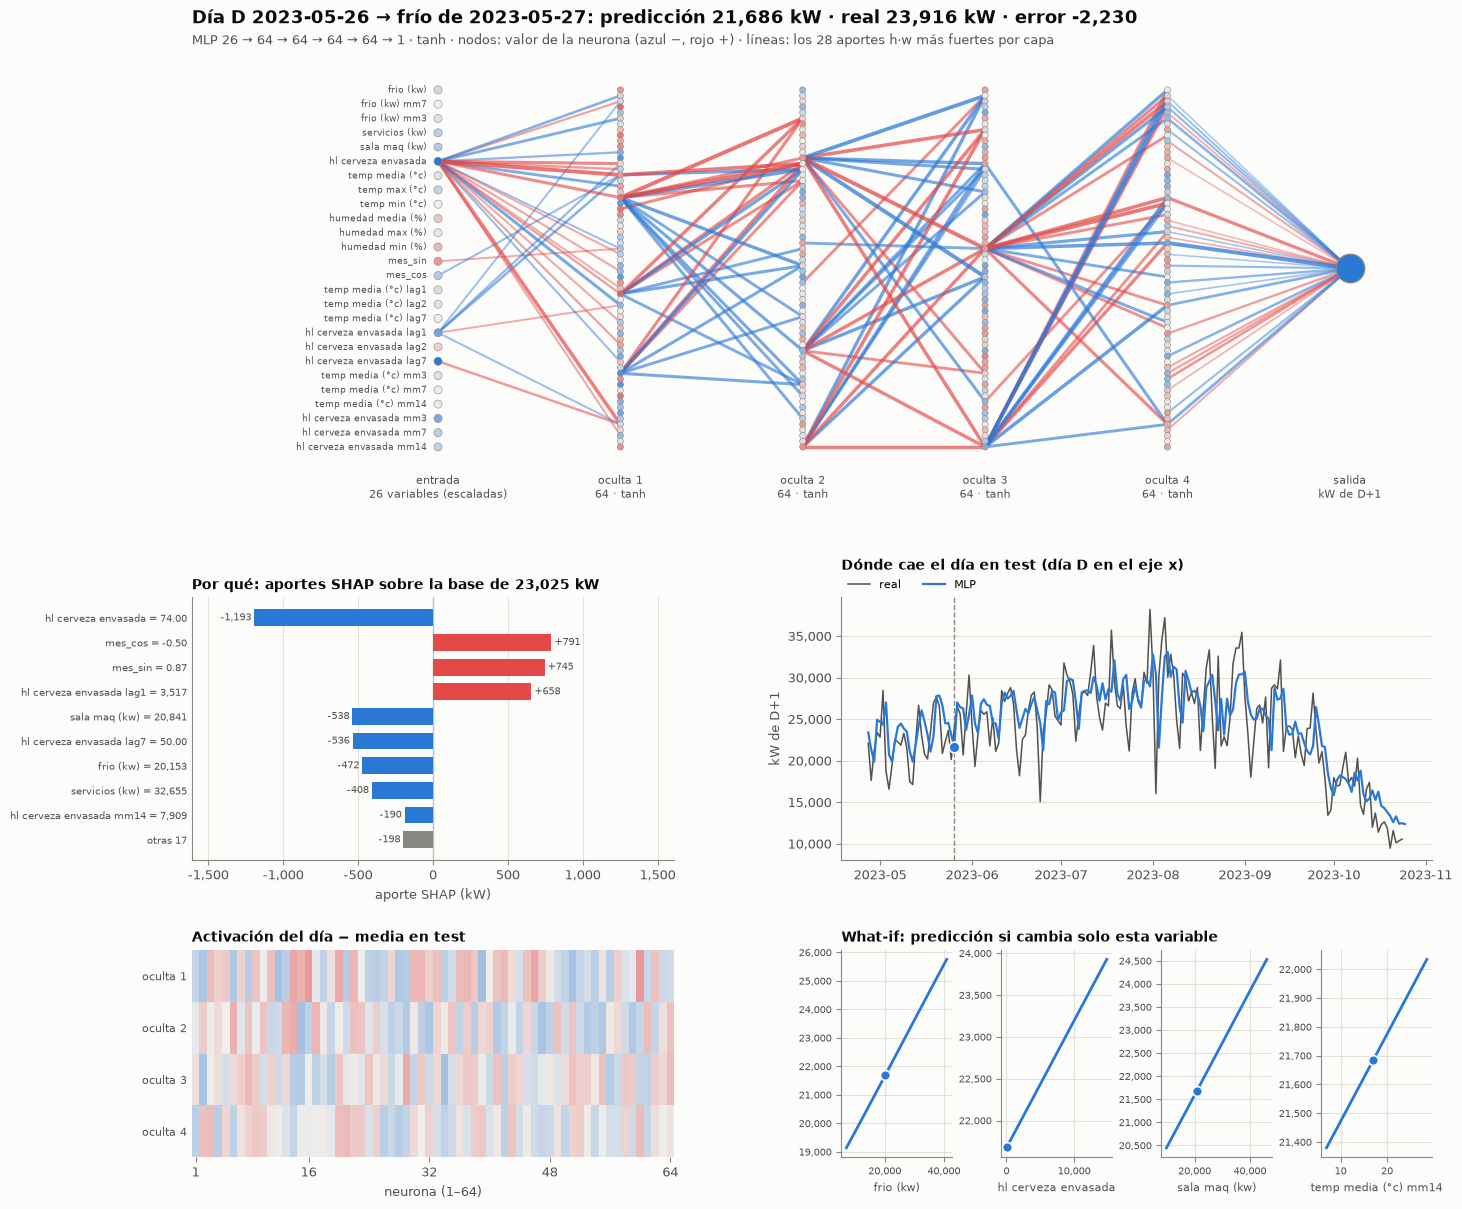

In [16]:
fig = dashboard(fecha_tipica)
guardar(fig, "dashboard_mlp")
plt.show()

## Conclusiones

- `mlp_v1.0.0` le gana a la persistencia en test (**≈16 % menos MAE**, R² 0.60) con días que nunca vio.
- Predice el frío de mañana sobre todo con **el frío reciente** (33 %), **la época del año** (20 %), **el consumo
  eléctrico de planta** (19 %) y **la producción** (16 %). La temperatura aporta poco por encima de eso (9 %).
- Las direcciones tienen sentido físico: más frío hoy, más producción, más consumo de planta y verano → más frío
  mañana.
- Por dentro **la red funciona casi como un modelo lineal**: activaciones lejos de la saturación, aportes SHAP
  rectos y curvas *what-if* rectas. Eso la hace fácil de explicar y estable, pero también dice que la profundidad
  (4 × 64) no se está aprovechando: una red mucho más chica o un modelo lineal bien regularizado podría rendir
  parecido.
- Los errores grandes son caídas bruscas de un día (paradas) sin señal previa en los datos: para atacarlas haría
  falta información del plan de producción o de mantenimiento del día siguiente.